Spectra functions imported
delta: 3.161072444210675e-05 - sigma: 2.9920830946304025e-05
gamma: 3.998598237967234e-05 - sigma: 2.9924757969231816e-05


c:\Users\microcelle1\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\microcelle1\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


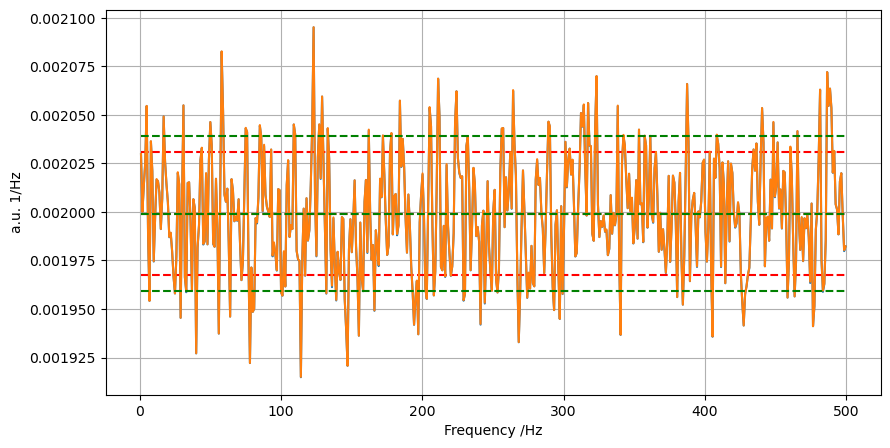

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from Spectra_lib import Spectra 
spec = Spectra()

# Parametri
N = 10000000        # numero di campioni
fs = 1000          # frequenza di campionamento [Hz]

# Generazione di due rumori bianchi indipendenti
rng = np.random.default_rng(42)

x = rng.normal(0, 1, N)
y = rng.normal(0, 1, N)
z = rng.normal(0, 1, N)
avg = 10000

f, Sx = spec.Csd(x+z, x+z, fs, avg, 'hann', N//avg)

f, Sy = spec.Csd(y+z, y+z, fs, avg, 'hann', N//avg)
        
f, Sxy = spec.Csd(x+z, y+z, fs, avg, 'hann', N//avg)
        

# Plot
plt.figure(figsize=(10, 5))


acc = 0
num = 0
val = []
img  = []
fr = []
for i in range(len(f)):
    if np.real(Sxy[i])>0:
        num = num + 1
        acc = acc + np.real(Sxy[i])
        val.append(np.real(Sxy[i]))
        img.append(np.imag(Sxy[i]))
        fr.append(f[i])
value = acc/num 
plt.plot(fr, val)

delta = np.mean(np.sqrt(Sy*Sx/(2*avg)+np.real(Sxy)**2/(2*avg)-np.imag(Sxy)**2/(2*avg)))
gamma = np.mean(np.sqrt(Sy*Sx/(avg)))

var_real =  np.sqrt(np.var(val,ddof=1))
var_abs = np.sqrt(np.var(np.abs(Sxy),ddof=1))

print(f"delta: {np.real(delta)} - sigma: {var_real}")
print(f"gamma: {np.real(gamma)} - sigma: {var_abs}")

plt.plot(f, (value)*np.ones(len(f)), '--', color="red")
plt.plot(f, (value+delta)*np.ones(len(f)), '--', color="red")
plt.plot(f, (value-delta)*np.ones(len(f)), '--', color="red")

plt.plot(f, np.abs(Sxy))
plt.plot(f, np.mean(np.abs(Sxy))*np.ones(len(f)), '--', color="green")
plt.plot(f, (np.mean(np.abs(Sxy))+gamma)*np.ones(len(f)), '--', color="green")
plt.plot(f, (np.mean(np.abs(Sxy))-gamma)*np.ones(len(f)), '--', color="green")


plt.xlabel("Frequency /Hz")
plt.ylabel("a.u. 1/Hz")
plt.grid(True)
plt.show()

Spectra functions imported


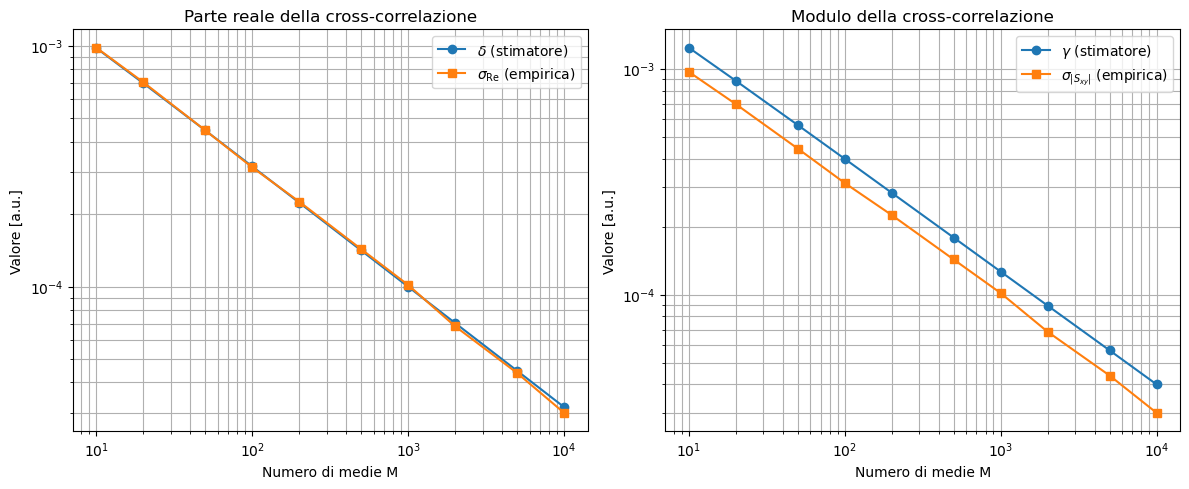

       M          delta       sigma_Re          gamma      sigma_abs
      10    9.78048e-04    9.81266e-04    1.23994e-03    9.69013e-04
      20    6.98971e-04    7.05670e-04    8.85240e-04    6.97603e-04
      50    4.44904e-04    4.45194e-04    5.63103e-04    4.42910e-04
     100    3.15381e-04    3.12627e-04    3.99049e-04    3.11897e-04
     200    2.23165e-04    2.25296e-04    2.82327e-04    2.24996e-04
     500    1.41230e-04    1.43017e-04    1.78672e-04    1.42928e-04
    1000    9.98801e-05    1.01547e-04    1.26336e-04    1.01512e-04
    2000    7.06014e-05    6.84417e-05    8.93265e-05    6.84333e-05
    5000    4.47171e-05    4.37744e-05    5.65640e-05    4.37647e-05
   10000    3.16107e-05    2.99208e-05    3.99860e-05    2.99248e-05


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from Spectra_lib import Spectra

spec = Spectra()

# Parametri
N = 10_000_000
fs = 1000

rng = np.random.default_rng(42)

x = rng.normal(0, 1, N)
y = rng.normal(0, 1, N)
z = rng.normal(0, 1, N)

# Numero di medie
M_values = np.array([
    10, 20, 50, 100, 200, 500,
    1000, 2000, 5000, 10000
])

delta_values = []
gamma_values = []
sigma_real_values = []
sigma_abs_values = []

for M in M_values:

    L = N // M

    f, Sx = spec.Csd(x + z, x + z, fs, M, 'hann', L)
    f, Sy = spec.Csd(y + z, y + z, fs, M, 'hann', L)
    f, Sxy = spec.Csd(x + z, y + z, fs, M, 'hann', L)

    # Stimatore dell'incertezza sulla parte reale
    delta = np.mean(np.sqrt(np.maximum(
        np.real(Sy * Sx) / (2 * M)
        + np.real(Sxy)**2 / (2 * M)
        - np.imag(Sxy)**2 / (2 * M),
        0
    )))

    # Stimatore dell'incertezza sul modulo
    gamma = np.mean(np.sqrt(
        np.maximum(np.real(Sy * Sx), 0) / M
    ))

    # Selezione delle frequenze con parte reale positiva
    mask = np.real(Sxy) > 0
    val = np.real(Sxy[mask])
    abs_val = np.abs(Sxy)

    # Dispersione empirica tra frequenze
    sigma_real = np.std(val, ddof=1)
    sigma_abs = np.std(abs_val, ddof=1)

    delta_values.append(delta)
    gamma_values.append(gamma)
    sigma_real_values.append(sigma_real)
    sigma_abs_values.append(sigma_abs)

# Conversione in array
delta_values = np.array(delta_values)
gamma_values = np.array(gamma_values)
sigma_real_values = np.array(sigma_real_values)
sigma_abs_values = np.array(sigma_abs_values)

# Grafici comparativi
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Parte reale: delta e sigma
ax[0].loglog(
    M_values, delta_values, 'o-',
    label=r'$\delta$ (stimatore)'
)
ax[0].loglog(
    M_values, sigma_real_values, 's-',
    label=r'$\sigma_{\mathrm{Re}}$ (empirica)'
)

ax[0].set_xlabel('Numero di medie M')
ax[0].set_ylabel('Valore [a.u.]')
ax[0].set_title('Parte reale della cross-correlazione')
ax[0].grid(True, which='both')
ax[0].legend()

# Modulo: gamma e sigma
ax[1].loglog(
    M_values, gamma_values, 'o-',
    label=r'$\gamma$ (stimatore)'
)
ax[1].loglog(
    M_values, sigma_abs_values, 's-',
    label=r'$\sigma_{|S_{xy}|}$ (empirica)'
)

ax[1].set_xlabel('Numero di medie M')
ax[1].set_ylabel('Valore [a.u.]')
ax[1].set_title('Modulo della cross-correlazione')
ax[1].grid(True, which='both')
ax[1].legend()

plt.tight_layout()
plt.show()

# Tabella numerica
print(
    f"{'M':>8} {'delta':>14} {'sigma_Re':>14} "
    f"{'gamma':>14} {'sigma_abs':>14}"
)

for i, M in enumerate(M_values):
    print(
        f"{M:8d} "
        f"{delta_values[i]:14.5e} "
        f"{sigma_real_values[i]:14.5e} "
        f"{gamma_values[i]:14.5e} "
        f"{sigma_abs_values[i]:14.5e}"
    )


Spectra functions imported


c:\Users\microcelle1\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\microcelle1\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


delta: 0.7653854200629954 - sigma: 0.5598687949384564
delta: 1.1792708326863626e-05 - sigma: 1.1494874904413185e-05


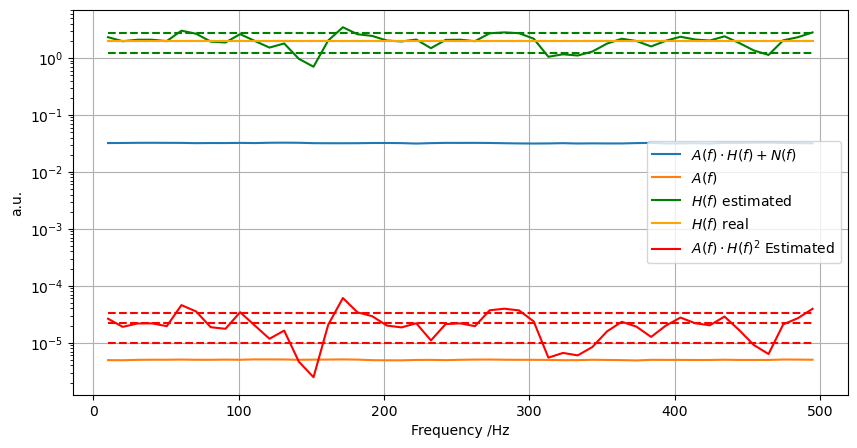

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from Spectra_lib import Spectra 
spec = Spectra()

# Parametri
N = 1000000       # numero di campioni
fs = 1000          # frequenza di campionamento [Hz]

# Generazione di due rumori bianchi indipendenti
rng = np.random.default_rng(42)

x = 0.05*rng.normal(0, 1, N)
y = 4*rng.normal(0, 1, N)
z = 1+rng.normal(0, 1, N)

H = 2
A = x*H+y
B = x

avg = 10000

f, Sx = spec.Csd(A, A, fs, avg, 'hann', N//avg)

f, Sy = spec.Csd(B, B, fs, avg, 'hann', N//avg)

f, Sxy = spec.Csd(A, B, fs, avg, 'hann', N//avg)

# Plot
plt.figure(figsize=(10, 5))

plt.semilogy(f,Sx, label = r"$A(f) \cdot H(f) + N(f)$")
plt.semilogy(f,Sy, label = r"$A(f)$")
gamma_2 = np.mean(np.abs(Sxy)**2/(Sx*Sy))
delta = np.sqrt(H**2*(1-gamma_2)/(gamma_2*avg))
var_H = np.sqrt(np.var(np.abs(Sxy)/Sy,ddof=1))
print(f"delta: {np.real(delta)} - sigma: {var_H}")

plt.semilogy(f,np.abs(Sxy)/Sy, label = r"$H(f)$ estimated", color = "green")
plt.semilogy(f,(np.mean(np.abs(Sxy)/Sy))*np.ones(len(f)),"--",color = "green")
plt.semilogy(f,(np.mean(np.abs(Sxy)/Sy) + delta)*np.ones(len(f)),"--",color = "green")
plt.semilogy(f,(np.mean(np.abs(Sxy)/Sy) - delta)*np.ones(len(f)),"--",color = "green")


plt.semilogy(f,H*np.ones(len(f)), label = r"$H(f)$ real", color = "orange")

AH_2 = Sy*(np.abs(Sxy)/Sy)**2

val_y = np.mean(Sy)
delta = np.sqrt(
        np.mean(AH_2)**2 * (2 - gamma_2) /
        (gamma_2 * avg)
    )
var_AH_2 = np.sqrt(np.var(AH_2,ddof=1))
print(f"delta: {np.real(delta)} - sigma: {var_AH_2}")

plt.semilogy(f,AH_2, label = r"$A(f)\cdot H(f)^2$ Estimated", color = "red")
plt.semilogy(f,(np.mean(AH_2))*np.ones(len(f)),"--",color = "red")
plt.semilogy(f,(np.mean(AH_2) + delta)*np.ones(len(f)),"--",color = "red")
plt.semilogy(f,(np.mean(AH_2) - delta)*np.ones(len(f)),"--",color = "red")

plt.xlabel("Frequency /Hz")
plt.ylabel("a.u.")
plt.grid(True)
plt.legend()
plt.show()

Spectra functions imported


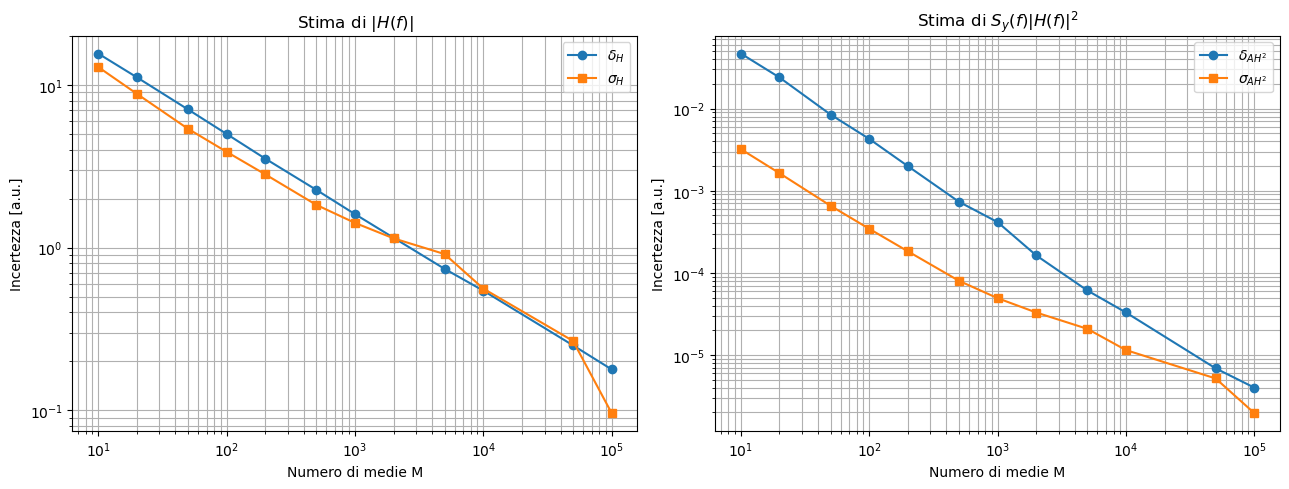

M       delta_H    sigma_H    delta_AH2    sigma_AH2
   10  1.55913e+01  1.28877e+01  4.67643e-02  3.20847e-03
   20  1.11405e+01  8.82127e+00  2.39092e-02  1.63473e-03
   50  7.07350e+00  5.37893e+00  8.45348e-03  6.55880e-04
  100  4.99751e+00  3.88109e+00  4.27544e-03  3.44223e-04
  200  3.52412e+00  2.82158e+00  1.99304e-03  1.83179e-04
  500  2.26505e+00  1.83155e+00  7.33715e-04  8.01109e-05
 1000  1.60665e+00  1.41904e+00  4.15099e-04  4.92523e-05
 2000  1.14969e+00  1.13995e+00  1.63308e-04  3.29538e-05
 5000  7.39834e-01  9.12200e-01  6.11099e-05  2.08603e-05
10000  5.43736e-01  5.59869e-01  3.29753e-05  1.14949e-05
50000  2.50716e-01  2.66951e-01  6.88504e-06  5.18860e-06
100000  1.78388e-01  9.60716e-02  4.01201e-06  1.96374e-06


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from Spectra_lib import Spectra

spec = Spectra()

# Parametri
N = 1_000_000
fs = 1000

rng = np.random.default_rng(42)

x = 0.05 * rng.normal(0, 1, N)
y = 4* rng.normal(0, 1, N)
z = 1 + rng.normal(0, 1, N)

H = 2

A = x * H + y
B = x

# Numero di medie da studiare
M_values = np.array([
    10, 20, 50, 100, 200, 500,
    1000, 2000, 5000, 10000, 50000, 100000
])

delta_H_values = []
sigma_H_values = []

delta_AH2_values = []
sigma_AH2_values = []

gamma2_values = []

for M in M_values:

    # Lunghezza dei segmenti
    L = N // M

    # Spettri
    f, Sx = spec.Csd(A, A, fs, M, 'hann', L)
    f, Sy = spec.Csd(B, B, fs, M, 'hann', L)
    f, Sxy = spec.Csd(A, B, fs, M, 'hann', L)

    # Coerenza quadratica media
    gamma_2 = np.mean(
        np.abs(Sxy)**2 / (Sx * Sy)
    )

    gamma2_values.append(gamma_2)

    # Stima di H(f)
    H_est = np.abs(Sxy) / Sy

    # Incertezza teorica su H
    delta_H = np.sqrt(
        np.mean(H_est)**2 * (1 - gamma_2) /
        (gamma_2 * M*2)
    )

    # Deviazione standard empirica su H
    sigma_H = np.std(H_est, ddof=1)

    delta_H_values.append(np.real(delta_H))
    sigma_H_values.append(sigma_H)

    # Stima di Sy * |H|^2
    AH_2 = Sy * H_est**2

    # Incertezza teorica su AH_2
    val_y = np.mean(Sy)

    delta_AH2 = np.sqrt(
        np.max(AH_2)**2 * (2 - gamma_2) /
        (gamma_2 * M)
    )

    # Deviazione standard empirica
    sigma_AH2 = np.std(AH_2, ddof=1)

    delta_AH2_values.append(np.real(delta_AH2))
    sigma_AH2_values.append(sigma_AH2)


# Conversione in array
delta_H_values = np.array(delta_H_values)
sigma_H_values = np.array(sigma_H_values)

delta_AH2_values = np.array(delta_AH2_values)
sigma_AH2_values = np.array(sigma_AH2_values)


# Grafici
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# H stimato
ax[0].loglog(
    M_values, delta_H_values, 'o-',
    label=r'$\delta_H$'
)
ax[0].loglog(
    M_values, sigma_H_values, 's-',
    label=r'$\sigma_H$'
)
ax[0].set_xlabel('Numero di medie M')
ax[0].set_ylabel('Incertezza [a.u.]')
ax[0].set_title(r'Stima di $|H(f)|$')
ax[0].grid(True, which='both')
ax[0].legend()

# Sy * |H|^2
ax[1].loglog(
    M_values, delta_AH2_values, 'o-',
    label=r'$\delta_{AH^2}$'
)
ax[1].loglog(
    M_values, sigma_AH2_values, 's-',
    label=r'$\sigma_{AH^2}$'
)
ax[1].set_xlabel('Numero di medie M')
ax[1].set_ylabel('Incertezza [a.u.]')
ax[1].set_title(r'Stima di $S_y(f)|H(f)|^2$')
ax[1].grid(True, which='both')
ax[1].legend()

plt.tight_layout()
plt.show()


# Valori numerici
print("M       delta_H    sigma_H    delta_AH2    sigma_AH2")
for i, M in enumerate(M_values):
    print(
        f"{M:5d}  "
        f"{delta_H_values[i]:.5e}  "
        f"{sigma_H_values[i]:.5e}  "
        f"{delta_AH2_values[i]:.5e}  "
        f"{sigma_AH2_values[i]:.5e}"
    )